/var/folders/br/nr4k1vxj1_j7jxk17x7xr8n9g2q0k8/T/ipykernel_63459/3130968732.py:44: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(data=melted, x='odor_num', y='pleasantness', hue='session',


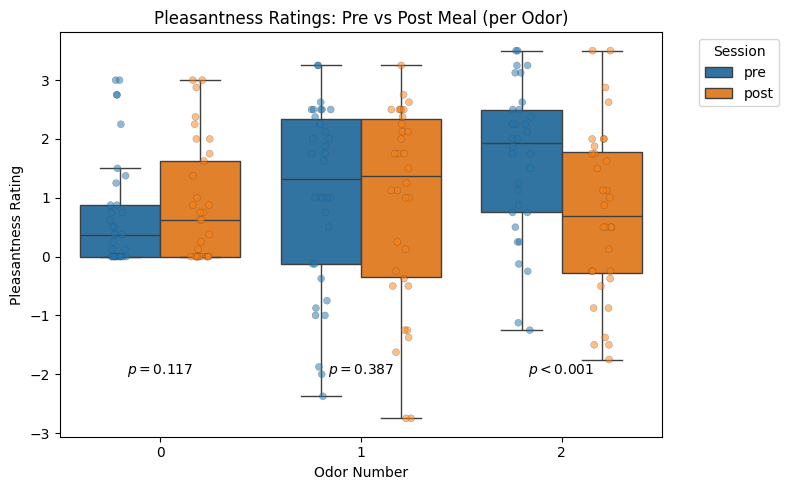

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy.stats import ttest_rel

# Load all subject summaries
processed_dir = Path('/Users/liuq13/SPCD_data/beh_processed')
all_data = []

for sub_dir in processed_dir.glob('sub-*'):
    summary_file = sub_dir / 'pleasantness_summary.csv'
    if summary_file.exists():
        df = pd.read_csv(summary_file)
        df['subject'] = sub_dir.name
        all_data.append(df)

# Combine
combined_df = pd.concat(all_data, ignore_index=True)

# Melt for plotting
melted = pd.melt(
    combined_df,
    id_vars=['subject', 'odor_num'],
    value_vars=['pre_mean', 'post_mean'],
    var_name='session',
    value_name='pleasantness'
)
melted['session'] = melted['session'].str.replace('_mean', '', regex=False)

# === Perform paired t-tests ===
results = []
for odor in sorted(combined_df['odor_num'].unique()):
    df_odor = combined_df[combined_df['odor_num'] == odor]
    stat, pval = ttest_rel(df_odor['pre_mean'], df_odor['post_mean'])
    results.append({'odor_num': odor, 'pval': pval})

# Merge into DataFrame
stat_df = pd.DataFrame(results)

# === Plot ===
plt.figure(figsize=(8, 5))
sns.boxplot(data=melted, x='odor_num', y='pleasantness', hue='session', fliersize=0, linewidth=1)
sns.stripplot(data=melted, x='odor_num', y='pleasantness', hue='session', 
              dodge=True, jitter=True, alpha=0.5, linewidth=0.3, edgecolor='gray')

# Clean up legend
handles, labels = plt.gca().get_legend_handles_labels()
plt.legend(handles[:2], labels[:2], title='Session', bbox_to_anchor=(1.05, 1), loc='upper left')

# Add p-value annotations
for i, row in stat_df.iterrows():
    x = i  # odor_num corresponds to x-axis category
    y = -2
    pval = row['pval']
    label = f"$p = {pval:.3f}$" if pval >= 0.001 else "$p < 0.001$"
    plt.text(x, y, label, ha='center', fontsize=10)

plt.title('Pleasantness Ratings: Pre vs Post Meal (per Odor)')
plt.xlabel('Odor Number')
plt.ylabel('Pleasantness Rating')
plt.tight_layout()
plt.show()
